# Fixing the CNN's memorizing (overfitting)

Same steps as `src/08_cnn_overfitting.py`, with explanations. *(Trains about 25 networks; around 30 minutes.)*

The first CNN learned the training engines almost perfectly (error about 3) but scored about 15 on new engines, and lost to gradient boosting on the test set (17.03 vs 15.18). That gap means it was **memorizing** the 100 training engines instead of learning general rules.

Three fixes, tested one at a time on the same five practice exams:
- **Dropout:** while learning, 30% of the network's signals are switched off at random, like a study group where random members are absent each day, so nobody can lean on one person.
- **Smaller network:** instead of remembering *where* in the clip each shape appeared, it only counts *how much* of each shape it saw. Less room to memorize.
- **Both together.**

Decided before looking at the test set: we also **average the 5 networks** trained from different random starts, like asking 5 students and taking the average answer.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import GroupKFold

from cmapss import (ENGINE_COLORS, PROJECT_ROOT, add_baseline_features, apply_scaler, clip_rul,
                    feature_columns, fit_scaler, load_test_with_rul, load_train, make_cnn,
                    make_windows, plot_predicted_vs_true, predict_cnn, rmse, train_cnn)

N_START, SMOOTH = 20, 10
MAX_EPOCHS = 60            # dropout and smaller networks usually need more passes
SEEDS = [0, 1, 2, 3, 4]
FIG = PROJECT_ROOT / "figures"
versions = {               # name -> options for make_cnn
    "first CNN (no fix)": {},
    "+ dropout": {"dropout": 0.3},
    "smaller network": {"pool": True},
    "smaller + dropout": {"pool": True, "dropout": 0.3},
}


def add_feats(df):
    return add_baseline_features(df, N_START, smooth=SMOOTH)


train = add_feats(clip_rul(load_train()))
original = feature_columns(train)
cols = (original + [c for c in train.columns if c.endswith("_chg")]
        + [c for c in train.columns if c.endswith(f"_chg_avg{SMOOTH}")])
for name, net in versions.items():
    print(f"{name:20s} {sum(p.numel() for p in make_cnn(len(cols), **net).parameters()):6d} learned numbers")


first CNN (no fix)    37153 learned numbers
+ dropout             37153 learned numbers
smaller network        6401 learned numbers
smaller + dropout      6401 learned numbers


## Five practice exams

For each version, the error is recorded after every epoch on the engines it studied and on held-out engines. The **gap** between the two is the memorizing: a big gap means it knows the practice questions but not the subject.

In [2]:
# --- Five practice exams ---------------------------------------------------
val_curves = {n: [] for n in versions}
train_curves = {n: [] for n in versions}
for k, (tr_idx, val_idx) in enumerate(GroupKFold(n_splits=5).split(train, groups=train["unit"]), 1):
    tr, val = train.iloc[tr_idx], train.iloc[val_idx]
    scaler = fit_scaler(tr, cols)
    Xtr, ytr, _ = make_windows(apply_scaler(tr, cols, scaler), cols)
    Xv, yv, _ = make_windows(apply_scaler(val, cols, scaler), cols)
    for name, net in versions.items():
        _, hist = train_cnn(Xtr, ytr, n_epochs=MAX_EPOCHS, seed=0, X_val=Xv, y_val=yv, **net)
        val_curves[name].append([h["val"] for h in hist])
        train_curves[name].append([h["train"] for h in hist])
        print(f"fold {k}  {name:20s} best held-out {min(h['val'] for h in hist):.2f}", flush=True)

print("\nPractice-exam average (gradient boosting on the same flights: 13.34)")
best_epoch, best_score = {}, {}
for name in versions:
    v, t = np.mean(val_curves[name], axis=0), np.mean(train_curves[name], axis=0)
    i = int(np.argmin(v))
    best_epoch[name], best_score[name] = i + 1, v[i]
    folds = " ".join(f"{c[i]:.1f}" for c in val_curves[name])
    # The "memorizing gap": error on new engines minus error on studied engines.
    print(f"  {name:20s} held-out {v[i]:.2f} at epoch {i + 1:2d}  studied {t[i]:.2f}  "
          f"gap {v[i] - t[i]:.2f}  | at epoch {MAX_EPOCHS}: held-out {v[-1]:.2f}, gap {v[-1] - t[-1]:.2f}"
          f"  | folds {folds}")


fold 1  first CNN (no fix)   best held-out 14.50


fold 1  + dropout            best held-out 16.05


fold 1  smaller network      best held-out 13.87


fold 1  smaller + dropout    best held-out 14.38


fold 2  first CNN (no fix)   best held-out 15.81


fold 2  + dropout            best held-out 17.68


... (11 outputs left out)

fold 5  + dropout            best held-out 15.71


fold 5  smaller network      best held-out 15.02


fold 5  smaller + dropout    best held-out 14.87



Practice-exam average (gradient boosting on the same flights: 13.34)
  first CNN (no fix)   held-out 15.20 at epoch  6  studied 8.03  gap 7.17  | at epoch 60: held-out 16.34, gap 14.28  | folds 14.5 16.1 15.3 14.8 15.2
  + dropout            held-out 16.75 at epoch 56  studied 10.42  gap 6.33  | at epoch 60: held-out 17.35, gap 6.49  | folds 16.1 18.8 14.7 17.1 17.0
  smaller network      held-out 14.64 at epoch 10  studied 8.69  gap 5.95  | at epoch 60: held-out 16.14, gap 12.84  | folds 13.9 14.3 14.5 14.5 16.1
  smaller + dropout    held-out 14.96 at epoch 14  studied 8.61  gap 6.35  | at epoch 60: held-out 15.75, gap 9.81  | folds 15.0 14.8 15.2 14.4 15.3


## Learning curves

Blue = studied engines, orange = held-out engines. A fix that works should keep the two lines closer together, and push orange lower.

saved figures/cnn_overfitting_fixes.png


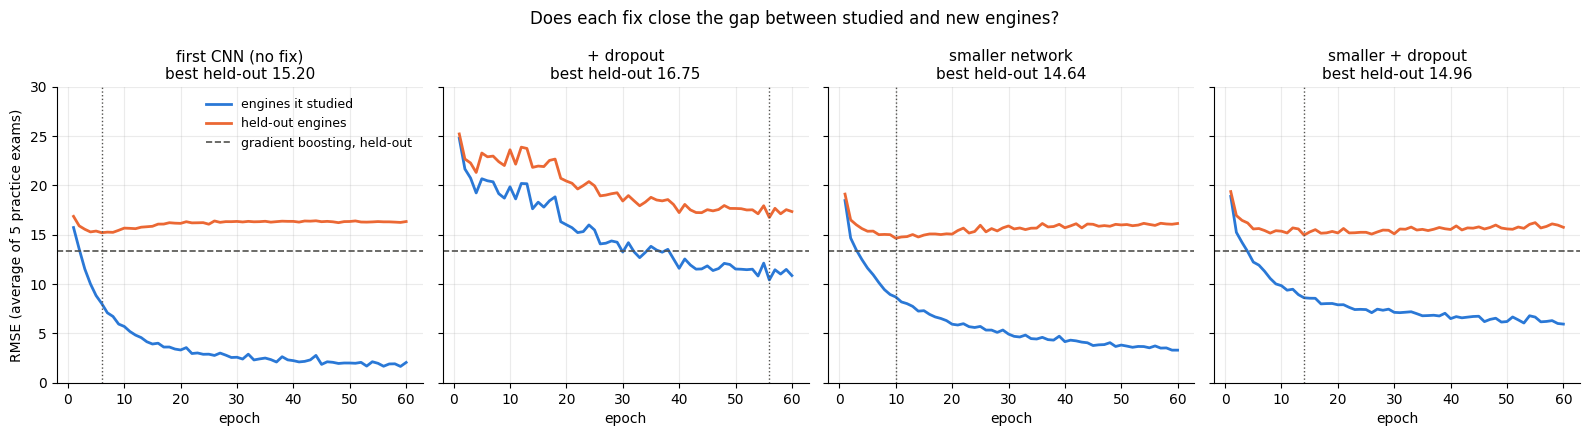

In [3]:
fig, axes = plt.subplots(1, len(versions), figsize=(16, 4.4), sharey=True)
ep = np.arange(1, MAX_EPOCHS + 1)
for ax, name in zip(axes, versions):
    ax.plot(ep, np.mean(train_curves[name], axis=0), color=ENGINE_COLORS[0], lw=2, label="engines it studied")
    ax.plot(ep, np.mean(val_curves[name], axis=0), color=ENGINE_COLORS[1], lw=2, label="held-out engines")
    ax.axhline(13.34, color="#52514e", ls="--", lw=1.2, label="gradient boosting, held-out")
    ax.axvline(best_epoch[name], color="#52514e", ls=":", lw=1)
    ax.set_title(f"{name}\nbest held-out {best_score[name]:.2f}", fontsize=11)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("RMSE (average of 5 practice exams)")
axes[0].set_ylim(0, 30)
axes[0].legend(frameon=False, fontsize=9, loc="upper right")
fig.suptitle("Does each fix close the gap between studied and new engines?", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "cnn_overfitting_fixes.png", dpi=150)
print("saved figures/cnn_overfitting_fixes.png")


## The test set, once

The practice exams choose the version and the number of epochs. We train 5 networks from different random starts, score each, then score their average.

In [4]:
# --- Choose by practice exams, then the test set once ------------------------
chosen = min(versions, key=best_score.get)
net, n_epochs = versions[chosen], best_epoch[chosen]
print(f"\nChosen by practice exams: {chosen}, {n_epochs} epochs")
scaler = fit_scaler(train, cols)
Xtr, ytr, _ = make_windows(apply_scaler(train, cols, scaler), cols)
test = add_feats(load_test_with_rul())
Xte, yte, _ = make_windows(apply_scaler(test, cols, scaler), cols, last_only=True)
near = yte <= 30

preds = []
for seed in SEEDS:
    model, _ = train_cnn(Xtr, ytr, n_epochs=n_epochs, seed=seed, **net)
    p = np.clip(predict_cnn(model, Xte), 0, None)
    preds.append(p)
    print(f"seed {seed}: test RMSE {rmse(yte, p):.2f}  too high {(p > yte).sum()}/100  "
          f"near-failure RMSE {rmse(yte[near], p[near]):.2f}", flush=True)
scores = [rmse(yte, p) for p in preds]
ens = np.mean(preds, axis=0)   # the 5 networks vote: average their guesses
print(f"\nsingle networks: average {np.mean(scores):.2f}, range {min(scores):.2f} to {max(scores):.2f}")
print(f"average of the 5 networks (ensemble): test RMSE {rmse(yte, ens):.2f}  "
      f"too high {(ens > yte).sum()}/100  near-failure RMSE {rmse(yte[near], ens[near]):.2f}  "
      f"near failure >20 too high: {int(((ens - yte) > 20)[near].sum())}")
print("(first CNN: 17.03 average; gradient boosting: 15.18)")



Chosen by practice exams: smaller network, 10 epochs


seed 0: test RMSE 16.96  too high 47/100  near-failure RMSE 6.60


seed 1: test RMSE 17.78  too high 43/100  near-failure RMSE 7.86


seed 2: test RMSE 17.60  too high 45/100  near-failure RMSE 6.06


seed 3: test RMSE 17.69  too high 40/100  near-failure RMSE 6.30


seed 4: test RMSE 17.23  too high 43/100  near-failure RMSE 7.91



single networks: average 17.45, range 16.96 to 17.78
average of the 5 networks (ensemble): test RMSE 16.84  too high 43/100  near-failure RMSE 5.85  near failure >20 too high: 0
(first CNN: 17.03 average; gradient boosting: 15.18)


saved figures/cnn_fixed_predicted_vs_true.png


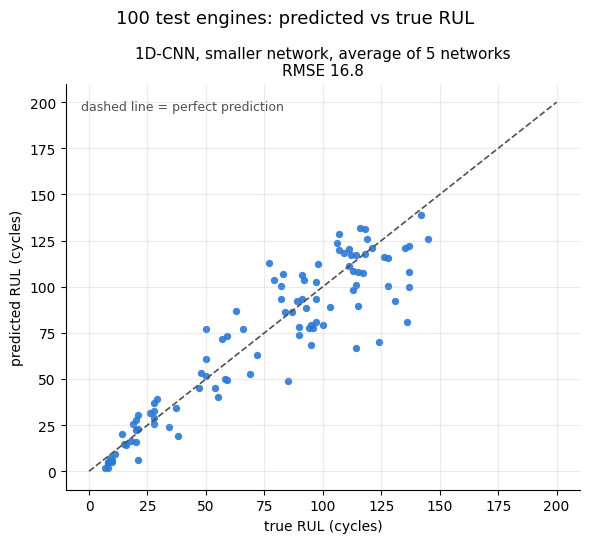

In [5]:
fig = plot_predicted_vs_true([(f"1D-CNN, {chosen}, average of 5 networks", yte, ens)],
                             "100 test engines: predicted vs true RUL", limit=200)
fig.savefig(FIG / "cnn_fixed_predicted_vs_true.png", dpi=150)
print("saved figures/cnn_fixed_predicted_vs_true.png")


## What we learned

- **The fixes shrank the memorizing gap a little, but did not help much on new engines.** Practice exams: first CNN 15.20, dropout 16.75, smaller network 14.64, smaller + dropout 14.96. The folds of each version spread by 1 to 4 flights, so only "dropout alone is worse" is clearly real.
- **Test set:** the chosen smaller network averaged 17.45 over 5 random starts (range 16.96 to 17.78), no better than the first CNN's 17.03. Averaging the 5 networks gave **16.84**, the best CNN result so far, but still worse than gradient boosting (15.18).
- **Averaging networks helps**, as expected: 16.84 beats every one of the 5 single networks (16.96 to 17.78).
- **Memorizing is not the main limit.** Whatever we do, the held-out error stays around 14.5 to 15 on the practice exams. Likely reason (not proven): with only 100 training engines and our hand-made clues already in place, gradient boosting simply suits this data better.
- **Dropout learns slowly.** Its held-out error was still falling at epoch 60, so it might do better with more epochs. Not tested.
